![Python Banner](../../Image/05_08_Quasi_Experiemnts.png)


# 8.3 Regression Discontinuity Design (RDD)



Regression Discontinuity Design (RDD) is a quasi-experimental method that exploits treatment assignment based on a threshold on a continuous running variable. Units just above and just below the cutoff are assumed to be comparable, allowing causal effect estimation at the threshold.

## Overview

### The Core Idea

When treatment is assigned by a **threshold on a continuous score**, units immediately above and below the cutoff are essentially identical except for treatment status. This creates a local randomization around the threshold, enabling causal effect estimation.

For example:

- Customers with credit score ≥ 700 get approved for a loan
- Students with test score ≥ 80 pass the exam
- Stores with performance score below 50 get a turnaround program
- Orders over $50 get free shipping

The key insight is that whether a unit ends up just above or just below the cutoff is effectively random — it depends on small fluctuations in the running variable. Comparing outcomes in a narrow window around the cutoff identifies the **local average treatment effect (LATE)** at the threshold.

### Business Setting

RDD is ideal when:

- Treatment is assigned by a **clear threshold** on a **continuous score**
- The threshold is **known and rule-based** (not manipulated)
- Units **cannot precisely manipulate** their score to sort around the cutoff
- You have **sufficient data near the cutoff** for estimation

Common business examples:

- Credit scoring: loan approval based on credit score thresholds
- Pricing: discounts for orders above a certain amount
- Performance management: interventions for underperforming stores/employees
- Churn prevention: retention calls for customers above a churn-risk threshold
- Academic testing: scholarships for students above a test score cutoff

### The Identifying Assumptions

RDD relies on two key assumptions:

1. **Continuity of potential outcomes**: Potential outcomes $Y(0)$ and $Y(1)$ are continuous functions of the running variable at the cutoff. Nothing else jumps at the threshold except treatment status.

2. **No precise manipulation**: Units cannot precisely control their score to end up on one side of the cutoff. While they may influence their score generally, they cannot fine-tune it to fall just above or below the threshold.

### Key Advantages

- **Internal validity**: RDD is often considered the most credible quasi-experimental design after RCTs
- **Transparent**: The cutoff is observable and the assumption of local randomization is intuitive
- **Visual**: The discontinuity in outcomes at the cutoff is directly visible in plots
- **Local effect**: Estimates the effect at the margin — exactly the policy-relevant question for threshold decisions
- **Falsifiable**: The assumptions can be tested with density tests and covariate continuity checks

## Implementation in Python

`RegressionDiscontinuity` fits a local linear model $Y = a + b(R-c) + \tau D + d(R-c)D$ inside a bandwidth around the cutoff. $\tau$ is the jump. The interval is a Bayesian bootstrap of the rows inside that window.

The setup matches the other PyCausalML tutorials: find the repository, import the package, and install the editable checkout only if the import fails.

## Set Up


In [1]:
import subprocess
import sys
from pathlib import Path

def _repo_root() -> Path:
    here = Path.cwd().resolve()
    for cand in [here, *here.parents]:
        if (cand / "pyproject.toml").is_file() and (cand / "src" / "pycausalml").is_dir():
            return cand
    raise FileNotFoundError(
        "PyCausalML repository was not found. Run this notebook from the repository."
    )

root = _repo_root()

try:
    import pycausalml  # noqa: F401
    print("PyCausalML ready.")
except ImportError:
    subprocess.check_call(
        [sys.executable, "-m", "pip", "install", "-q", "-e", f"{root}[plot]"],
    )
    print("PyCausalML installed.")
print("Repository:", root)


PyCausalML ready.
Repository: /home/zia207/Github/PyCausalML


In [2]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from pycausalml import (
    RegressionDiscontinuity,

)

rng = np.random.default_rng(42)
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
print("Imported PyCausalML")


Imported PyCausalML


## Simulated Example: Churn-Risk Threshold

We'll simulate a scenario where customers with churn-risk score ≥ 0.7 receive a retention call. This lets us know the true effect and verify that RDD recovers it.

In [3]:
n = 6000
score = rng.uniform(0, 1, n)  # churn-risk score
cutoff = 0.7
D = (score >= cutoff).astype(int)  # treatment: retention call

TRUE_RD = 6.5  # true effect: call adds $6.5 in customer value

# Outcome: customer value depends on score (quadratic) + treatment
y = 40 - 25*score + 8*score**2 + TRUE_RD*D + rng.normal(0, 5, n)

rd = pd.DataFrame(dict(score=score, D=D, y=y))

print(rd.head())
print(f"\nTrue effect at cutoff: ${TRUE_RD}")

   score  D      y
0  0.774  1 26.758
1  0.439  0 32.982
2  0.859  1 27.895
3  0.697  0 18.211
4  0.094  0 36.279

True effect at cutoff: $6.5


## Visualize with Binned Means

Always plot first — a discontinuity you can't see in a binned scatter is rarely robust. Binning reduces noise and makes the pattern visible.

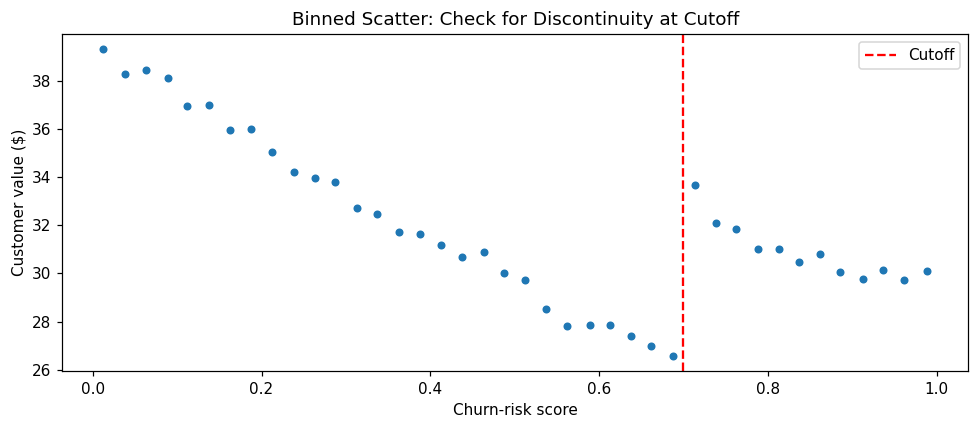

In [4]:
# Bin the data and compute means
rd["bin"] = pd.cut(rd.score, bins=40)
binned = rd.groupby("bin", observed=True).agg(
    x=("score", "mean"), 
    y=("y", "mean")
)

# Plot
plt.figure(figsize=(9, 4))
plt.scatter(binned.x, binned.y, s=18)
plt.axvline(cutoff, color="red", ls="--", label="Cutoff")
plt.xlabel("Churn-risk score")
plt.ylabel("Customer value ($)")
plt.title("Binned Scatter: Check for Discontinuity at Cutoff")
plt.legend()
plt.tight_layout()
plt.show()

You should see a jump at the cutoff (score = 0.7). If there's no visible discontinuity, RDD is unlikely to find a significant effect.

## Local Linear Estimation

The estimator fits a straight line on each side of the cutoff, inside a bandwidth, and reads the jump at the cutoff. A narrower window reduces bias from curvature. A wider window uses more rows and tightens the interval. The summary reports the jump and a 95% Bayesian bootstrap interval.


In [5]:

bandwidth = 0.15
rd_fit = RegressionDiscontinuity(cutoff=cutoff, bandwidth=bandwidth, n_boot=200, random_state=0)
rd_fit.fit(rd["score"].to_numpy(), rd["y"].to_numpy())
print(pd.Series(rd_fit.summary()).round(3))
print(f"True effect at cutoff: ${TRUE_RD}")


estimate         6.871
ci_lower         5.929
ci_upper         7.845
posterior_mean   6.890
dtype: float64
True effect at cutoff: $6.5


The summary reports:

- **estimate**: the jump at the cutoff
- **ci_lower** and **ci_upper**: the 95% interval from the Bayesian bootstrap
- **posterior_mean**: the mean of those draws

The estimate should sit near the true effect of $6.5.


## RDD Plot

Binned means show the raw pattern. Local linear fits on each side show the jump the estimator uses.


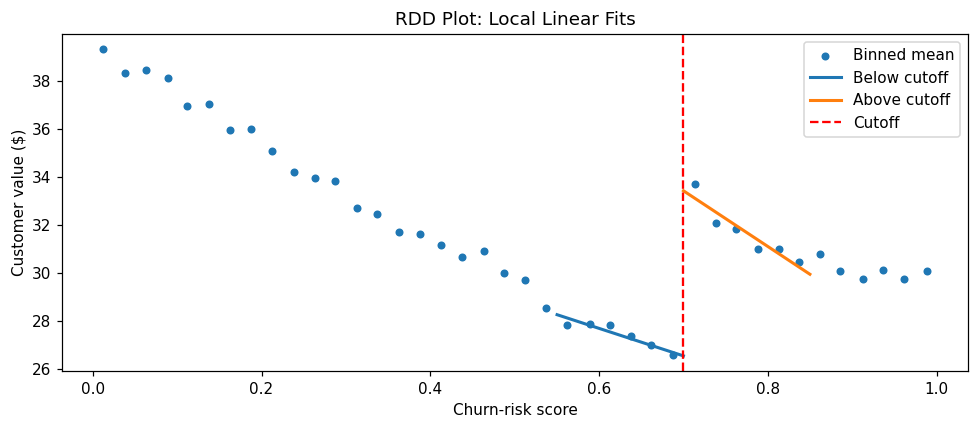

In [6]:

def local_line(x, y, c, bandwidth, right):
    if right:
        mask = (x >= c) & (x <= c + bandwidth)
    else:
        mask = (x < c) & (x >= c - bandwidth)
    design = np.column_stack([np.ones(mask.sum()), x[mask] - c])
    beta = np.linalg.lstsq(design, y[mask], rcond=None)[0]
    grid = np.linspace(x[mask].min(), x[mask].max(), 40)
    return grid, beta[0] + beta[1] * (grid - c)

fig, ax = plt.subplots(figsize=(9, 4))
ax.scatter(binned.x, binned.y, s=18, label="Binned mean")
for right, name in [(False, "Below cutoff"), (True, "Above cutoff")]:
    grid, pred = local_line(rd.score.to_numpy(), rd.y.to_numpy(), cutoff, bandwidth, right)
    ax.plot(grid, pred, lw=2, label=name)
ax.axvline(cutoff, color="red", ls="--", label="Cutoff")
ax.set_xlabel("Churn-risk score")
ax.set_ylabel("Customer value ($)")
ax.set_title("RDD Plot: Local Linear Fits")
ax.legend()
fig.tight_layout()
plt.show()


The plot shows binned means and a local linear fit on each side of the cutoff. The vertical gap between those lines at the cutoff is the RDD estimate. The numerical interval is in the summary above.


## Validity Checks

RDD assumptions are falsifiable — we can test them with several diagnostic checks.

### 1. Manipulation Test (McCrary Density Test)

If units can precisely manipulate their scores to end up on one side of the cutoff, the density of the running variable will jump at the threshold. The McCrary test checks for this.

Rows in [0.65, 0.7): 303
Rows in [0.70, 0.75): 275


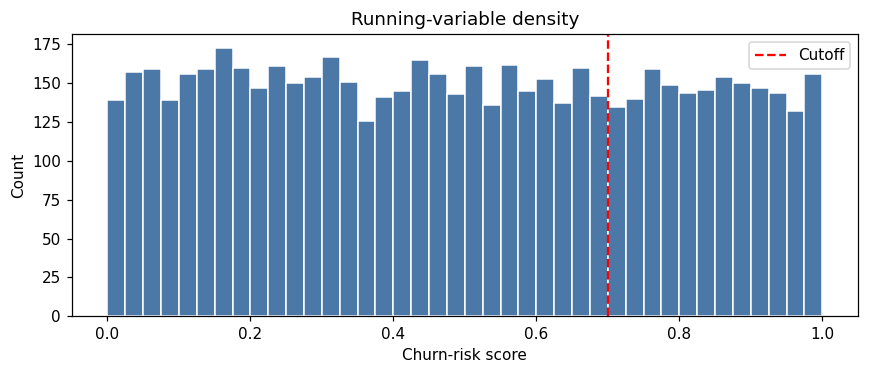

In [7]:

window = 0.05
left_n = int(((rd.score >= cutoff - window) & (rd.score < cutoff)).sum())
right_n = int(((rd.score >= cutoff) & (rd.score < cutoff + window)).sum())
print(f"Rows in [{cutoff - window:.2f}, {cutoff}): {left_n}")
print(f"Rows in [{cutoff:.2f}, {cutoff + window:.2f}): {right_n}")

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(rd.score, bins=40, color="#4C78A8", edgecolor="white")
ax.axvline(cutoff, color="red", ls="--", label="Cutoff")
ax.set_xlabel("Churn-risk score")
ax.set_ylabel("Count")
ax.set_title("Running-variable density")
ax.legend()
fig.tight_layout()
plt.show()


The null hypothesis is no manipulation (no jump in density). A significant p-value suggests manipulation, which would violate RDD assumptions.

**Note**: In our simulated data, there should be no manipulation (p-value > 0.05).

### 2. Covariate Continuity

Pre-treatment covariates should **not** jump at the cutoff. If they do, it suggests that units above and below the cutoff differ systematically, violating the local randomization assumption.

Let's add a covariate (customer tenure) and test its continuity:

In [8]:

rd["tenure"] = 3 + 2 * rd.score + rng.normal(0, 0.5, n)
tenure_fit = RegressionDiscontinuity(cutoff=cutoff, bandwidth=bandwidth, n_boot=150, random_state=1)
tenure_fit.fit(rd["score"].to_numpy(), rd["tenure"].to_numpy())
print("Covariate continuity (tenure should not jump):")
print(pd.Series(tenure_fit.summary()).round(3))


Covariate continuity (tenure should not jump):
estimate         -0.020
ci_lower         -0.112
ci_upper          0.083
posterior_mean   -0.016
dtype: float64


The effect on tenure should be statistically insignificant (close to zero). If it's significant, it suggests the cutoff divides different types of customers.

### 3. Placebo Cutoffs

Estimate the effect at fake cutoffs (e.g., 0.5, 0.6, 0.8). Effects at these placebo cutoffs should be approximately zero.

In [9]:

placebo_cutoffs = [0.50, 0.60, 0.80]
print("Placebo cutoffs (the interval should cover zero when the window excludes the real cutoff):")
for fake in placebo_cutoffs:
    fit = RegressionDiscontinuity(cutoff=fake, bandwidth=0.08, n_boot=80, random_state=0)
    fit.fit(rd["score"].to_numpy(), rd["y"].to_numpy())
    summary = fit.summary()
    print(
        f"Cutoff {fake:.2f}: estimate = {summary['estimate']:.3f}, "
        f"interval = [{summary['ci_lower']:.3f}, {summary['ci_upper']:.3f}]"
    )


Placebo cutoffs (the interval should cover zero when the window excludes the real cutoff):
Cutoff 0.50: estimate = -0.122, interval = [-1.469, 0.998]
Cutoff 0.60: estimate = 0.774, interval = [-0.411, 1.988]
Cutoff 0.80: estimate = -0.032, interval = [-1.461, 1.183]


### 4. Bandwidth Sensitivity

Check whether the estimate is stable across different bandwidth choices. The estimate should not change dramatically with reasonable bandwidth variations.

In [10]:

print("Bandwidth sensitivity:")
for bw in [0.05, 0.10, 0.15, 0.20, 0.25]:
    fit = RegressionDiscontinuity(cutoff=cutoff, bandwidth=bw, n_boot=80, random_state=0)
    fit.fit(rd["score"].to_numpy(), rd["y"].to_numpy())
    summary = fit.summary()
    print(
        f"Bandwidth {bw:.2f}: estimate = {summary['estimate']:.3f}, "
        f"interval = [{summary['ci_lower']:.3f}, {summary['ci_upper']:.3f}]"
    )


Bandwidth sensitivity:
Bandwidth 0.05: estimate = 8.520, interval = [6.943, 10.088]
Bandwidth 0.10: estimate = 7.664, interval = [6.747, 8.765]
Bandwidth 0.15: estimate = 6.871, interval = [6.058, 7.761]
Bandwidth 0.20: estimate = 6.756, interval = [6.094, 7.555]
Bandwidth 0.25: estimate = 6.751, interval = [6.051, 7.450]


The estimates should be relatively stable across bandwidths. Large swings suggest the result is sensitive to the bandwidth choice.

## Fuzzy RDD

In a **sharp RDD**, treatment status is deterministic at the cutoff (all units above are treated, all below are untreated). In a **fuzzy RDD**, crossing the threshold only *increases the probability* of treatment — some units above may not be treated, and some below may be treated.

For example:
- Customers with score ≥ 0.7 *should* get a call, but not all do (some agents skip calls)
- Some customers below the threshold still get calls (exceptions)

In fuzzy RDD, the cutoff becomes an **instrument** for treatment, and the estimand is a LATE at the cutoff (effect on compliers whose treatment status is moved by the cutoff).

In [11]:

n_fuzzy = 4000
score_fuzzy = rng.uniform(0, 1, n_fuzzy)
p_treat = np.where(score_fuzzy >= cutoff, 0.8, 0.2)
D_fuzzy = rng.binomial(1, p_treat)
y_fuzzy = 40 - 25 * score_fuzzy + 8 * score_fuzzy**2 + TRUE_RD * D_fuzzy + rng.normal(0, 5, n_fuzzy)

jump_y = RegressionDiscontinuity(cutoff=cutoff, bandwidth=bandwidth, n_boot=120, random_state=0)
jump_y.fit(score_fuzzy, y_fuzzy)
jump_d = RegressionDiscontinuity(cutoff=cutoff, bandwidth=bandwidth, n_boot=120, random_state=1)
jump_d.fit(score_fuzzy, D_fuzzy.astype(float))
late = jump_y.effect_ / jump_d.effect_
print(f"Jump in the outcome: {jump_y.effect_:.2f}")
print(f"Jump in treatment probability: {jump_d.effect_:.2f}")
print(f"Fuzzy LATE (ratio of the jumps): {late:.2f}")
print(f"True effect: {TRUE_RD}")


Jump in the outcome: 4.18
Jump in treatment probability: 0.59
Fuzzy LATE (ratio of the jumps): 7.06
True effect: 6.5


The fuzzy RDD estimate is the LATE for compliers — units whose treatment status is actually moved by crossing the cutoff.

## Real-World Data

The series below is a real dataset shipped with [CausalPy](https://causalpy.readthedocs.io/en/stable/) (PyMC Labs), under the Apache License 2.0. The files live in [`causalpy/data`](https://github.com/pymc-labs/CausalPy/tree/main/causalpy/data).

```
@software{causalpy,
  author = {{PyMC Labs}},
  title = {CausalPy: Causal inference for quasi-experiments in Python},
  url = {https://github.com/pymc-labs/CausalPy},
  year = {2026}
}
```

PyCausalML fits the estimator. CausalPy is the data source. When CausalPy is installed, `causalpy.load_data` reads the packaged file. Otherwise the notebook reads the same CSV from that GitHub directory.

The drinking-age series is the minimum legal drinking age study used in CausalPy's regression-discontinuity example. `agecell` is age in years. `all` is the all-cause death rate. The cutoff is 21. See Carpenter and Dobkin, and the [CausalPy drinking example](https://causalpy.readthedocs.io/en/stable/).


CausalPy is not installed. Loaded 'drinking' from
https://raw.githubusercontent.com/pymc-labs/CausalPy/main/causalpy/data/drinking.csv
Install the package with: pip install 'pycausalml[causalpy]'
Shape (48, 20).
estimate          9.753
ci_lower          6.418
ci_upper         12.430
posterior_mean    9.818
dtype: float64


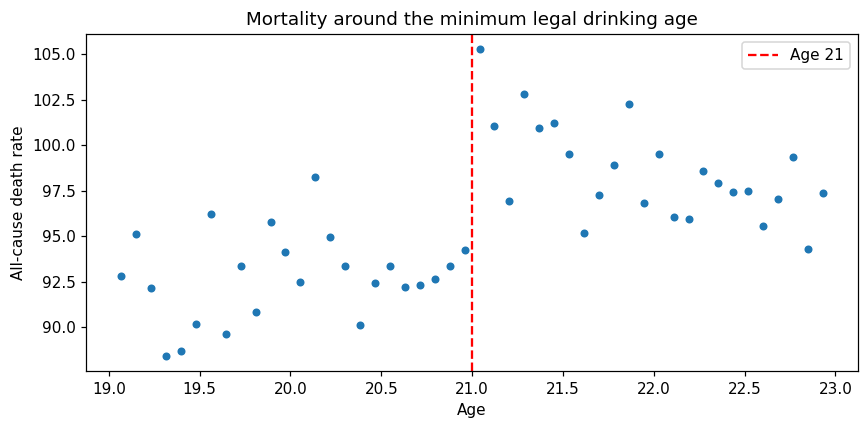

In [12]:
CAUSALPY_FILES = {
    "banks": "banks.csv",
    "covid": "deaths_and_temps_england_wales.csv",
    "drinking": "drinking.csv",
    "risk": "AJR2001.csv",
    "schoolReturns": "schoolingReturns.csv",
    "california_prop99": "california_prop99.csv",
}

def load_causalpy(name: str) -> pd.DataFrame:
    """Load a CausalPy example dataset.

    Uses causalpy.load_data when that package is installed. Otherwise reads
    the same CSV from the CausalPy GitHub data directory.
    """
    try:
        import causalpy as cp
        frame = cp.load_data(name)
        print(f"Loaded {name!r} with causalpy.load_data. Shape {frame.shape}.")
        return frame
    except ImportError:
        url = (
            "https://raw.githubusercontent.com/pymc-labs/CausalPy/main/causalpy/data/"
            + CAUSALPY_FILES[name]
        )
        frame = pd.read_csv(url)
        print(f"CausalPy is not installed. Loaded {name!r} from")
        print(url)
        print("Install the package with: pip install 'pycausalml[causalpy]'")
        print(f"Shape {frame.shape}.")
        return frame

drinking = load_causalpy("drinking").rename(columns={"agecell": "age"})
rd_age = RegressionDiscontinuity(cutoff=21, bandwidth=1.0, n_boot=200, random_state=0)
rd_age.fit(drinking["age"].to_numpy(), drinking["all"].to_numpy())
print(pd.Series(rd_age.summary()).round(3))

fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(drinking["age"], drinking["all"], s=18)
ax.axvline(21, color="red", ls="--", label="Age 21")
ax.set_xlabel("Age")
ax.set_ylabel("All-cause death rate")
ax.set_title("Mortality around the minimum legal drinking age")
ax.legend()
fig.tight_layout()
plt.show()


## Common Pitfalls

### 1. Manipulation of the Running Variable

If units can precisely control their score to end up on one side of the cutoff, the local randomization assumption fails.

**Examples**:
- Teachers inflating test scores to get students above a passing threshold
- Salespeople nudging order amounts just above a discount threshold

**Solution**: Compare how many units sit just above and just below the cutoff. A one-sided pile-up means the running variable was manipulated and RDD is not credible.


### 2. Other Discontinuities at the Cutoff

If other variables jump at the cutoff (e.g., a policy change affecting both treatment and outcome), the effect may be confounded.

**Solution**: Test covariate continuity and check for co-occurring policy changes.

### 3. Insufficient Data Near the Cutoff

With too few observations near the cutoff, estimates are unstable and bandwidths become very large (far from local).

**Solution**: Ensure sufficient sample size. Consider wider cutoff definition or alternative methods.

### 4. Wrong Functional Form

Using a linear fit when the true relationship is highly non-linear can bias estimates, especially with wide bandwidths.

**Solution**: Keep the local linear fit and check that the estimate is stable across bandwidths.


### 5. Extrapolating Beyond the Cutoff

RDD estimates the **local** effect at the cutoff. It does not license claims about effects far from the threshold.

**Example**: Finding that a retention call is worth $6.5 for customers at score 0.7 does **not** mean it's worth $6.5 for customers at score 0.9 or 0.5.

**Solution**: Be explicit with stakeholders that the effect is local to the cutoff.

## When to Use RDD

RDD is the right choice when:

- Treatment is assigned by a **clear threshold** on a **continuous score**
- The threshold is **rule-based and transparent**
- Units **cannot precisely manipulate** their scores
- You have **sufficient data near the cutoff**
- You care about the **local effect at the margin** (e.g., should we move the threshold?)

Consider alternatives when:

- No clear threshold → DiD, SCM, IV
- Manipulation is detected → Instrumental variables or other methods
- Effect far from cutoff is needed → Extrapolate cautiously or use other methods
- Insufficient data near cutoff → Aggregate or use alternative designs

## Summary

Regression Discontinuity Design is one of the most credible quasi-experimental methods, providing rigorous causal effect estimates when treatment is assigned by a threshold. Its strength lies in the transparency of the local randomization assumption and the extensive falsification tests available.

**Key takeaways:**

- RDD exploits threshold-based treatment assignment to estimate local effects
- Units just above and below the cutoff are as good as randomized
- Always visualize with binned means before estimation
- Fit the local linear jump with `RegressionDiscontinuity` and check the bandwidth
- Run validity checks: manipulation test, covariate continuity, placebo cutoffs
- Be explicit that effects are local to the cutoff, not generalizable
- Fuzzy RDD handles cases where the cutoff only increases treatment probability


## Scientific Terminology

Plain-language definitions for the terms in this tutorial are in the [scientific terminology glossary](../00-scientific-terminology-glossary.qmd).
